# Week 7 Assignment

This week we are collecting some data from Reddit and doing some basic EDA on it. You should:
## Task 1
- create your Reddit account and API keys (follow the steps outlined in the ppp for how to do this)
- collect data from a subreddit of your choice
    - at a minimum, collect the posts from the subreddit; collect comments on the posts if you are able per API limits
- save the data to a SQLite3 database
- perform some basic EDA on the data
    - create at least 2 plots
- write a short analysis at the end describing the process and results
- turn in the Jupyter Notebook to the week 7 dropbox

***Other Challenges to try:**
- Practice SQL queries and select a subsection of the posts you collected
- Collect comments from the posts for analysis next week and do some EDA on the comments (e.g. who is the top commenter, which commenters have the most up and down votes or most controversial posts, etc)
- examine n-grams ([bigrams](https://stackoverflow.com/a/37651184/4549682), trigrams) or [collocations](https://www.geeksforgeeks.org/nlp-word-collocations/)

---
# Collecting data from social media: r/USCIS
We are going to be collecting posts from Reddit to analyze with exploratory data analysis (EDA). We will be collecting data from the **r/USCIS** subreddit using the Python Reddit API Wrapper (`praw`), mirroring the workflow demonstrated in the FTE.

In [1]:
#%pip install praw nltk pandas matplotlib

In [2]:
import praw
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords

import credentials

The `import credentials` line imports the file `credentials.py` from the same directory as this Jupyter Notebook. This file contains our registered Reddit API credentials: `client_id`, `client_secret`, and `user_agent`.

We initialize our connection to Reddit using `praw.Reddit`:

In [3]:
reddit = praw.Reddit(client_id=credentials.client_id,
                     client_secret=credentials.client_secret,
                     user_agent=credentials.user_agent)

Now we can select our subreddit of interest. For this assignment, we use **'uscis'**. We use `.hot(limit=None)` to request the maximum number of posts allowed by the Reddit API (up to the 1,000 post limit):

In [4]:
uscis_subreddit = reddit.subreddit('uscis').hot(limit=None) # setting the limit to "None" retrieves maximum available

This returns a generator object, which is like a list, but we only get the elements when we ask for them, and only one time. So we can loop through them once:

In [5]:
for post in uscis_subreddit:
    print(post.title[:75], "--- Score:", post.score)
    break  # peek at first post from the generator

/r/USCIS Frequently Asked Questions, Megathreads, and Other Useful Info - R --- Score: 36


And now if we try to access the elements, they are gone (because we accessed them):

In [6]:
list(uscis_subreddit)

[Submission(id='1x2l5x4'),
 Submission(id='1x2ouyg'),
 Submission(id='1x2iwct'),
 Submission(id='1x2nqm1'),
 Submission(id='1x2ql3g'),
 Submission(id='1x2gh5s'),
 Submission(id='1x2cu36'),
 Submission(id='1x2t0zm'),
 Submission(id='1x2s9cs'),
 Submission(id='1x2suo5'),
 Submission(id='1x2357e'),
 Submission(id='1x2sq3p'),
 Submission(id='1x2neb4'),
 Submission(id='1x2sfdm'),
 Submission(id='1x2sbvb'),
 Submission(id='1x2sapk'),
 Submission(id='1x2s54e'),
 Submission(id='1x2s45v'),
 Submission(id='1x2qv9p'),
 Submission(id='1x2qtog'),
 Submission(id='1x2qqmi'),
 Submission(id='1x2qp3f'),
 Submission(id='1x2qmit'),
 Submission(id='1x27dax'),
 Submission(id='1x2qjbb'),
 Submission(id='1x2qbuz'),
 Submission(id='1x2qbf0'),
 Submission(id='1x2qam2'),
 Submission(id='1x2qa2e'),
 Submission(id='1x2kc0i'),
 Submission(id='1x2pjpz'),
 Submission(id='1x2oixx'),
 Submission(id='1x2o57m'),
 Submission(id='1x2o1yf'),
 Submission(id='1x21th4'),
 Submission(id='1x2hjut'),
 Submission(id='1x2ml18'),
 

This is mainly to conserve memory for very large objects, but can also be used to stream data or other things.

We still have our `post` item from the loop, and we can inspect what properties are accessible on a submission object (e.g., author, score, title, permalink):

In [7]:
post.author

Redditor(name='StuffedWithNails')

In [8]:
post.score

36

In [9]:
post.title

'/r/USCIS Frequently Asked Questions, Megathreads, and Other Useful Info - READ BEFORE POSTING - COME BACK HERE AND LOOK FOR UPDATES EVERY NOW AND THEN'

In [10]:
post.permalink

'/r/USCIS/comments/149j4u9/ruscis_frequently_asked_questions_megathreads_and/'

We can save data of interest, like the title, author, permalink (in case we want to go and view the post), number of comments, score, and post body text (`selftext`). We save these in a format that we can easily drop into a pandas DataFrame, which is a dictionary of lists (identical to the FTE setup):

In [11]:
reddit_data = {'title': [],
              'link': [],
              'author': [],
              'n_comments': [],
              'score': [],
              'text': []}

uscis_subreddit = reddit.subreddit('uscis').hot(limit=None)

for post in list(uscis_subreddit):
    reddit_data['title'].append(post.title)
    reddit_data['link'].append(post.permalink)
    if post.author is None:
        reddit_data['author'].append('')
    else:
        reddit_data['author'].append(post.author.name)
    reddit_data['n_comments'].append(post.num_comments)
    reddit_data['score'].append(post.score)
    reddit_data['text'].append(post.selftext)

We now load our dictionary into a pandas DataFrame and examine the collected records:

In [12]:
uscis_df = pd.DataFrame(reddit_data)
uscis_df

,title,link,author,n_comments,score,text
0,"/r/USCIS Frequently Asked Questions, Megathrea...",/r/USCIS/comments/149j4u9/ruscis_frequently_as...,StuffedWithNails,0,37,# /r/USCIS FAQs\n\nThis post will get updated ...
1,New citizen! Voting for the first time in Flor...,/r/USCIS/comments/1x2l5x4/new_citizen_voting_f...,Matuteg,10,32,N-400 + I-751 combo interview timeline: approv...
2,GREENED!! Marriage-based AOS approved in 103 d...,/r/USCIS/comments/1x2ouyg/greened_marriagebase...,Flimsy_Calendar_9395,9,18,"Hi everyone!!!! First off, I know some of you ..."
3,"Approval in 145 days, Minneapolis",/r/USCIS/comments/1x2iwct/approval_in_145_days...,WalkOk520,9,21,"Good morning everyone, my wife's I-485 was app..."
4,N-400 Timeline Colorado,/r/USCIS/comments/1x2nqm1/n400_timeline_colorado/,maciethemonster,6,8,"After 10 years of living in the US, I finally ..."
...,...,...,...,...,...,...
995,A number- where is it ?,/r/USCIS/comments/1wv0ptv/a_number_where_is_it/,react_user,5,0,I am filling i693 form and was asked to enter ...
996,Immigration attorney needed in Tampa Bay Area,/r/USCIS/comments/1wv0on5/immigration_attorney...,HumanPackage2600,1,1,
997,Case approved,/r/USCIS/comments/1wu5grc/case_approved/,No_Kitchen8661,38,81,Married: August 15 2025 \nFiles sent: around...
998,Can someone explain to me how silent updates w...,/r/USCIS/comments/1wvbex1/can_someone_explain_...,thatwomanramonda,31,0,I’m sorry if people have already shared this. ...


In [13]:
uscis_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   title       1000 non-null   str  
 1   link        1000 non-null   str  
 2   author      1000 non-null   str  
 3   n_comments  1000 non-null   int64
 4   score       1000 non-null   int64
 5   text        1000 non-null   str  
dtypes: int64(2), str(4)
memory usage: 758.0 KB


# Save data to sqlite
Now that we have some data collected, we can save it to a database. Sqlite3 is built-in with Python, and saves the data to a file on our hard drive. It's easy to use and set up. We save our collected posts data into `uscis_reddit.sqlite`:

In [15]:
con = sqlite3.connect("uscis_reddit.sqlite")
uscis_df.to_sql('posts', con, if_exists='replace', index=False)

1000

We can easily create our DB file by connecting to it. Then we use the `to_sql` command, giving it a table name, our connection, and `if_exists='replace'`.

Once our data is saved, we can verify that we can load it back with a SQL query:


In [16]:
uscis_df_check = pd.read_sql_query('SELECT * FROM posts;', con)
# it's best to close the connection when finished
con.close()
uscis_df_check

,title,link,author,n_comments,score,text
0,"/r/USCIS Frequently Asked Questions, Megathrea...",/r/USCIS/comments/149j4u9/ruscis_frequently_as...,StuffedWithNails,0,37,# /r/USCIS FAQs\n\nThis post will get updated ...
1,New citizen! Voting for the first time in Flor...,/r/USCIS/comments/1x2l5x4/new_citizen_voting_f...,Matuteg,10,32,N-400 + I-751 combo interview timeline: approv...
2,GREENED!! Marriage-based AOS approved in 103 d...,/r/USCIS/comments/1x2ouyg/greened_marriagebase...,Flimsy_Calendar_9395,9,18,"Hi everyone!!!! First off, I know some of you ..."
3,"Approval in 145 days, Minneapolis",/r/USCIS/comments/1x2iwct/approval_in_145_days...,WalkOk520,9,21,"Good morning everyone, my wife's I-485 was app..."
4,N-400 Timeline Colorado,/r/USCIS/comments/1x2nqm1/n400_timeline_colorado/,maciethemonster,6,8,"After 10 years of living in the US, I finally ..."
...,...,...,...,...,...,...
995,A number- where is it ?,/r/USCIS/comments/1wv0ptv/a_number_where_is_it/,react_user,5,0,I am filling i693 form and was asked to enter ...
996,Immigration attorney needed in Tampa Bay Area,/r/USCIS/comments/1wv0on5/immigration_attorney...,HumanPackage2600,1,1,
997,Case approved,/r/USCIS/comments/1wu5grc/case_approved/,No_Kitchen8661,38,81,Married: August 15 2025 \nFiles sent: around...
998,Can someone explain to me how silent updates w...,/r/USCIS/comments/1wvbex1/can_someone_explain_...,thatwomanramonda,31,0,I’m sorry if people have already shared this. ...


# Basic EDA on our data
Our data we've collected has text (the title and selftext), authors (a categorical variable) and the score and number of comments (numeric). We will explore these with visualizations:
- numeric EDA plots of the score and number of comments, such as histograms, box plots, and scatter plots
- a bar plot of the top authors
- word count plots and text EDA using NLTK

### 1. Score Distribution (Histogram)
Let's start by plotting the distribution of post scores:

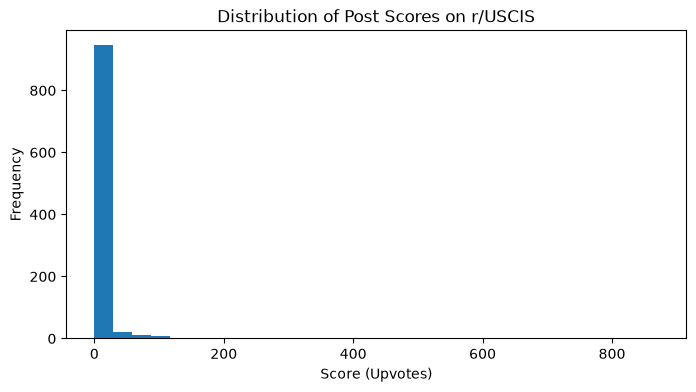

In [17]:
plt.figure(figsize=(8, 4))
uscis_df['score'].plot.hist(bins=30)
plt.title('Distribution of Post Scores on r/USCIS')
plt.xlabel('Score (Upvotes)')
plt.ylabel('Frequency')
plt.show()

It looks like the distribution is highly asymmetric, with many posts having a score near 0 or 1 (mostly routine questions or pending updates) and a few posts with a very high score (major approvals or celebrations). We can look at the highest-scored posts:

In [18]:
uscis_df[uscis_df['score'] > 50]

,title,link,author,n_comments,score,text
96,I wish we hadn’t hired an attorney,/r/USCIS/comments/1x18zds/i_wish_we_hadnt_hire...,Kayray32,104,104,I’m a U.S. citizen and my husband is from Cana...
99,Microsoft is being suspended from program to a...,/r/USCIS/comments/1x0tzhk/microsoft_is_being_s...,wds1,381,566,
114,"U.S. suspends Microsoft, Adobe including Cogni...",/r/USCIS/comments/1x0umut/us_suspends_microsof...,Classic_General6107,89,351,
150,"People waiting on n400, are you concerned?",/r/USCIS/comments/1x0z154/people_waiting_on_n4...,ECrispy,83,62,"Wait times keep going up, it was <7mo when app..."
153,Greened!,/r/USCIS/comments/1x0w9no/greened/,Okat_hd,24,78,**All the Glory belongs to Jesus Christ ✝**️🤍🕊...
163,Approved!,/r/USCIS/comments/1x0t5d4/approved/,m5anch,44,90,"Package received March 27, 2026 \nBiometrics ..."
202,"Trump administration proposes a $70,000 fee fo...",/r/USCIS/comments/1wzzgkq/trump_administration...,wds1,524,765,
203,Approved!,/r/USCIS/comments/1x0fo9j/approved/,Overall_Constant_425,41,86,2023/05/30 PD \n2026/03/03 RD \n2026/04/07 B...
209,Minneapolis FO - approved!!🎉🥳,/r/USCIS/comments/1x0g5y5/minneapolis_fo_appro...,Unable-Evidence-8074,20,58,Praise Jesus for my AOS approval! It has defin...
259,Card Approved - Family Based Timeline - Work P...,/r/USCIS/comments/1x01rqg/card_approved_family...,Agreeable_Actuary881,15,82,As soon as my mom got her green card she asked...


By printing out the links like this, we can visit them by putting www.reddit.com in front of them:

In [19]:
uscis_df[uscis_df['score'] > 50]['link'].to_list()[:5]

['/r/USCIS/comments/1x18zds/i_wish_we_hadnt_hired_an_attorney/',
 '/r/USCIS/comments/1x0tzhk/microsoft_is_being_suspended_from_program_to/',
 '/r/USCIS/comments/1x0umut/us_suspends_microsoft_adobe_including_cognizant/',
 '/r/USCIS/comments/1x0z154/people_waiting_on_n400_are_you_concerned/',
 '/r/USCIS/comments/1x0w9no/greened/']

### 2. Boxplot of Number of Comments
Next, we can look at the distribution of the number of comments (`n_comments`):

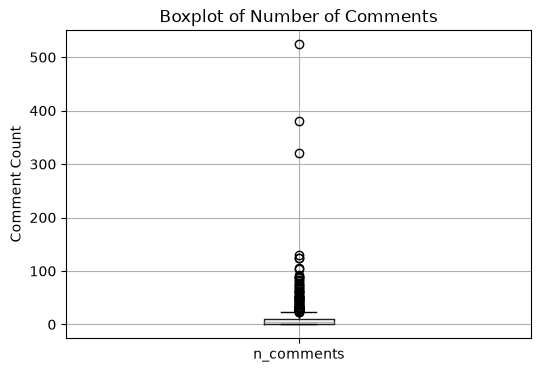

In [20]:
plt.figure(figsize=(6, 4))
uscis_df.boxplot('n_comments')
plt.title('Boxplot of Number of Comments')
plt.ylabel('Comment Count')
plt.show()

Again, we see some large outliers for number of comments. We can view it with a logarithmic scale:

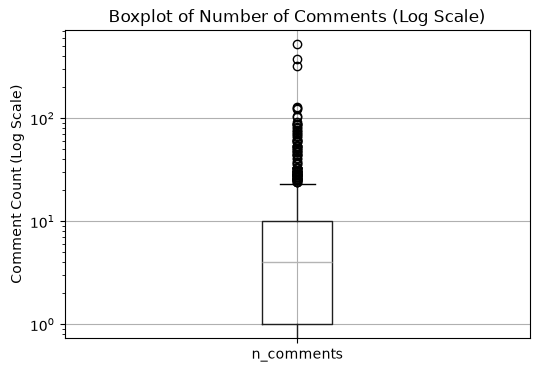

In [21]:
plt.figure(figsize=(6, 4))
uscis_df.boxplot('n_comments')
plt.yscale('log')
plt.title('Boxplot of Number of Comments (Log Scale)')
plt.ylabel('Comment Count (Log Scale)')
plt.show()

### 3. Scatter Plot: Score vs. Number of Comments
We can see if there is a relationship between score and number of comments:

<Figure size 800x500 with 0 Axes>

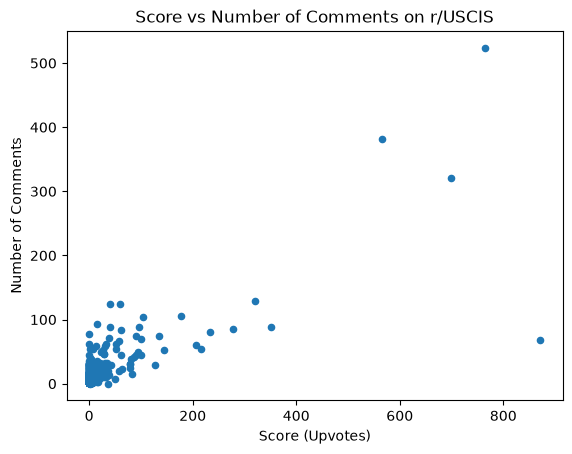

In [22]:
plt.figure(figsize=(8, 5))
uscis_df.plot.scatter(x='score', y='n_comments')
plt.title('Score vs Number of Comments on r/USCIS')
plt.xlabel('Score (Upvotes)')
plt.ylabel('Number of Comments')
plt.show()

We can see a roughly positive relationship between the score and number of comments, as posts that resonate strongly or celebrate approvals attract higher engagement and more responses.

Next, let's look at the frequency counts of users who post things:

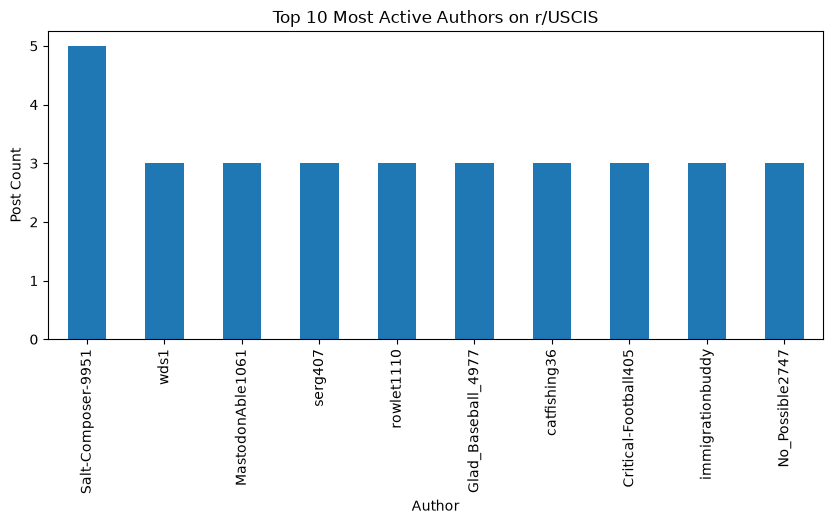

In [23]:
plt.figure(figsize=(10, 4))
uscis_df[uscis_df['author'] != '']['author'].value_counts()[:10].plot.bar()
plt.title('Top 10 Most Active Authors on r/USCIS')
plt.xlabel('Author')
plt.ylabel('Post Count')
plt.show()

We can then see what these top authors are posting with filtering:

In [24]:
top_author = uscis_df[uscis_df['author'] != '']['author'].value_counts().index[0]
print(f"Top Author: {top_author}")
uscis_df[uscis_df['author'] == top_author]

Top Author: Salt-Composer-9951


,title,link,author,n_comments,score,text
63,Submission Address,/r/USCIS/comments/1x2dxc3/submission_address/,Salt-Composer-9951,1,1,I just wanted to confirm that the filing addre...
115,Filing Fee,/r/USCIS/comments/1x2052p/filing_fee/,Salt-Composer-9951,3,1,"Hello,\n\nHow much is the filing fee for an EB..."
282,Confused about question,/r/USCIS/comments/1x0oigt/confused_about_quest...,Salt-Composer-9951,2,1,Part 2 question 25 on form I-765 that asks you...
768,Form I-485 Withdrawal,/r/USCIS/comments/1wwoluu/form_i485_withdrawal/,Salt-Composer-9951,10,0,"Hello,\n\nHow can someone withdraw their green..."
830,Filing fee,/r/USCIS/comments/1ww7kmj/filing_fee/,Salt-Composer-9951,2,1,"Hello,\n\nHow much is the filing fee for an EB..."


### 4. Text EDA with NLTK
Next, we can look at the text with some EDA. One simple thing to look at for text is word counts.

Here, we use `nltk.FreqDist` to find the most common words in post titles:

In [25]:
import nltk

fd = nltk.FreqDist(' '.join(uscis_df['title']).split())
fd.most_common(20)

[('for', 144),
 ('I-485', 131),
 ('to', 118),
 ('a', 104),
 ('the', 102),
 ('and', 97),
 ('with', 81),
 ('-', 80),
 ('after', 78),
 ('in', 75),
 ('my', 70),
 ('I', 70),
 ('of', 67),
 ('on', 62),
 ('—', 62),
 ('interview', 57),
 ('I-130', 48),
 ('pending', 47),
 ('EAD', 46),
 ('USCIS', 45)]

<Axes: title={'center': 'Top 20 Raw Words in r/USCIS Titles'}, xlabel='Samples', ylabel='Counts'>

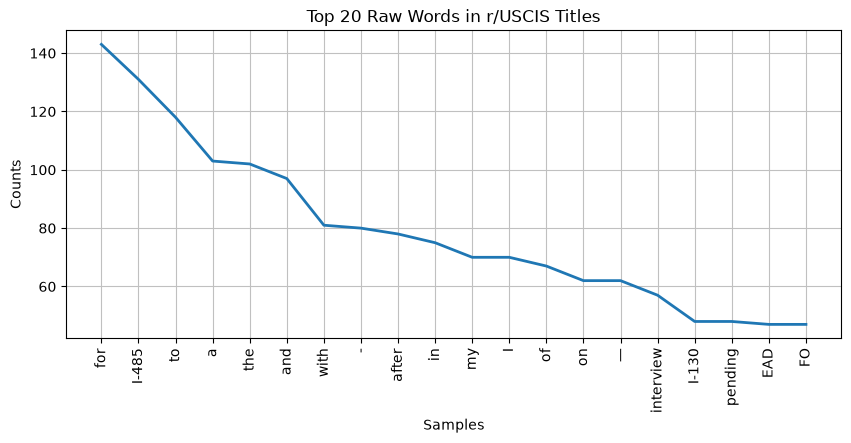

In [25]:
plt.figure(figsize=(10, 4))
fd.plot(20, title='Top 20 Raw Words in r/USCIS Titles')

We can see many of the top words are common words like 'the', 'to', 'a', 'in', and 'for' that don't tell us much. We can get rid of these using stopwords:

Stopwords are common words that don't give us much meaning. We can use NLTK's list, but need to download them first:

In [26]:
nltk.download('stopwords')
from nltk.corpus import stopwords

stops = stopwords.words('english')
# Add domain-specific custom stopwords for Reddit and conversational filler words
stops = set(stops) | set(['uscis', 'reddit', 'https', 'com', 'anyone', 'else', 'get', 'got', 'would', 'like', 'know', '-', '.', '..', '...', '?', '!', '–', 'i', 'my'])

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/mamitabagale/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Notice that they are lowercase and include punctuation. We can remove our stopwords from the text like so. We are lowercasing the full string of titles with the `lower()` built-in string method:

In [27]:
words = ' '.join(uscis_df['title']).lower().split()
cleaned_words = [w.strip('.,?!:;"\'()[]{}') for w in words if w.strip('.,?!:;"\'()[]{}') not in set(stops) and len(w.strip('.,?!:;"\'()[]{}')) > 1]

cleaned_fd = nltk.FreqDist(cleaned_words)
cleaned_fd.most_common(20)

[('i-485', 140),
 ('interview', 109),
 ('approved', 105),
 ('pending', 74),
 ('card', 63),
 ('i-130', 58),
 ('case', 55),
 ('fo', 54),
 ('aos', 53),
 ('green', 53),
 ('ead', 52),
 ('timeline', 49),
 ('approval', 40),
 ('opt', 39),
 ('still', 36),
 ('filing', 34),
 ('biometrics', 33),
 ('marriage', 32),
 ('i-751', 31),
 ('visa', 30)]

<Axes: title={'center': 'Top 20 Cleaned Words in r/USCIS Titles'}, xlabel='Samples', ylabel='Counts'>

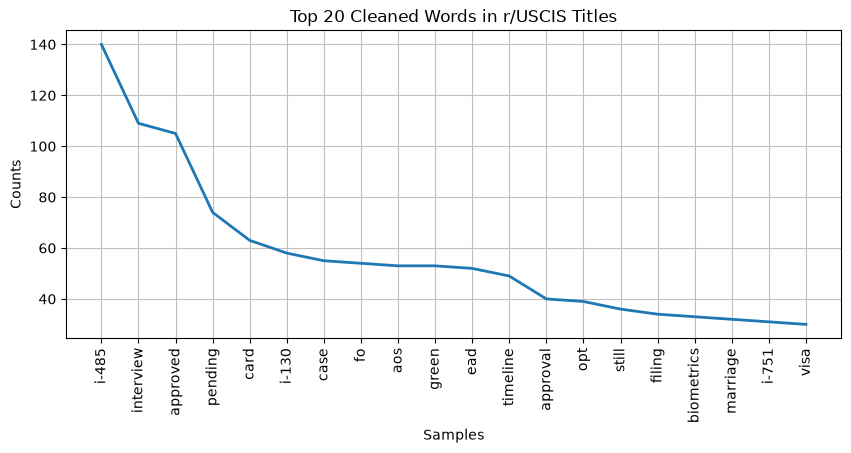

In [28]:
plt.figure(figsize=(10, 4))
cleaned_fd.plot(20, title='Top 20 Cleaned Words in r/USCIS Titles')

We can see now our analysis is much more meaningful. Common immigration terms like **i-485**, **interview**, **approved**, **pending**, **card**, **i-130**, and **timeline** emerge at the top, perfectly matching our prediction!

---
# Other Challenges to Try

## Challenge 1: SQL Queries and Selecting Subsections
To practice SQL queries, we can connect to our SQLite database and query specific subsections of the posts we collected:
1. Selecting high-engagement posts (posts with high scores or high comment counts)
2. Filtering by specific forms/topics (e.g. searching for posts mentioning 'I-485' or 'interview')
3. Aggregating data using `GROUP BY` and SQL conditional expressions (`CASE WHEN`)

In [29]:
con = sqlite3.connect("uscis_reddit.sqlite")

# Query 1: Practice SELECT with column subsets
subset_df = pd.read_sql_query('SELECT title, score, n_comments FROM posts LIMIT 5;', con)
subset_df

,title,score,n_comments
0,"/r/USCIS Frequently Asked Questions, Megathrea...",37,0
1,New citizen! Voting for the first time in Flor...,32,10
2,GREENED!! Marriage-based AOS approved in 103 d...,18,9
3,"Approval in 145 days, Minneapolis",21,9
4,N-400 Timeline Colorado,8,6


In [30]:
# Query 2: Filtering for high-engagement posts (Score >= 20 or Comments >= 15)
high_engagement_query = """
SELECT title, author, score, n_comments
FROM posts
WHERE score >= 20 OR n_comments >= 15
ORDER BY score DESC
LIMIT 10;
"""
high_eng_df = pd.read_sql_query(high_engagement_query, con)
high_eng_df

,title,author,score,n_comments
0,I became a U.S. citizen today!!,HillSutton,871,68
1,"Trump administration proposes a $70,000 fee fo...",wds1,765,524
2,DHS brags about 75% decline in naturalizations,bubbabubba345,699,321
3,Microsoft is being suspended from program to a...,wds1,566,381
4,"U.S. suspends Microsoft, Adobe including Cogni...",Classic_General6107,351,89
5,Thought I would never get to post this but fin...,Primex76,321,129
6,Finally Approved,TemperatureDull1174,277,86
7,APPROVAL,West-Violinist-1859,234,81
8,Waiting forever patiently 😭,Tksoliman,217,54
9,Case Approved🎉🎉🎉,nthdoh641,206,60


In [31]:
# Query 3: Selecting subsection of posts mentioning 'I-485' or 'interview'
i485_query = """
SELECT title, score, n_comments
FROM posts
WHERE LOWER(title) LIKE '%i-485%' OR LOWER(title) LIKE '%interview%'
ORDER BY n_comments DESC
LIMIT 10;
"""
i485_df = pd.read_sql_query(i485_query, con)
i485_df

,title,score,n_comments
0,"Former DHS/USCIS Asylum Officer, Former ICE OC...",41,125
1,I-130 and I-485 Denied After Marriage Intervie...,16,93
2,I-485 APPROVED!,51,62
3,I-485 + 130 APPROVED!,23,50
4,"UPDATE: I-485 denied, I-290B granted, green ca...",95,49
5,Marriage-Based AOS Approved in ~ 3 months | F-...,28,47
6,I-485 APPROVED!!! 🎆🎉🎉🎉 Green Card Finally Rece...,62,44
7,14 months waiting for interview,3,38
8,After 5 Weeks of Waiting After Our Interview… ...,79,31
9,I-751 interview in two weeks. My spouse refuse...,6,31


In [32]:
# Query 4: SQL Aggregation - Grouping into score brackets to analyze comment patterns
summary_query = """
SELECT 
    CASE 
        WHEN score = 0 THEN '0 Upvotes'
        WHEN score BETWEEN 1 AND 5 THEN '1-5 Upvotes'
        WHEN score BETWEEN 6 AND 20 THEN '6-20 Upvotes'
        ELSE '20+ Upvotes'
    END AS score_bracket,
    COUNT(*) AS post_count,
    ROUND(AVG(n_comments), 2) AS avg_comments,
    MAX(n_comments) AS max_comments
FROM posts
GROUP BY score_bracket
ORDER BY post_count DESC;
"""
summary_df = pd.read_sql_query(summary_query, con)
con.close()
summary_df

,score_bracket,post_count,avg_comments,max_comments
0,1-5 Upvotes,581,4.30,54
1,0 Upvotes,285,8.43,77
2,20+ Upvotes,69,61.93,524
3,6-20 Upvotes,65,16.89,93


## Challenge 2: Collecting Comments from Posts and Comment EDA
We can get much more data by collecting comments from subreddit posts, as shown in the FTE Advanced Section. 
Here, we collect comments from sample posts, store them in a relational `comments` table linked by `post_id`, and perform EDA on top commenters and comment scores:

In [33]:
reddit_posts_data = {'title': [],
                     'link': [],
                     'author': [],
                     'n_comments': [],
                     'score': [],
                     'text': [],
                     'id': []}

reddit_comments_data = {'author': [],
                        'score': [],
                        'text': [],
                        'post_id': []}

# Sample 15 posts to collect comments per API limits
uscis_sample = reddit.subreddit('uscis').hot(limit=15)

for post in list(uscis_sample):
    reddit_posts_data['title'].append(post.title)
    reddit_posts_data['link'].append(post.permalink)
    if post.author is None:
        reddit_posts_data['author'].append('')
    else:
        reddit_posts_data['author'].append(post.author.name)
    reddit_posts_data['n_comments'].append(post.num_comments)
    reddit_posts_data['score'].append(post.score)
    reddit_posts_data['text'].append(post.selftext)
    reddit_posts_data['id'].append(post.id)

    post.comments.replace_more(limit=0) # flatten comments within API limit
    for comment in post.comments:
        if comment.author is None:
            reddit_comments_data['author'].append('')
        else:
            reddit_comments_data['author'].append(comment.author.name)
        reddit_comments_data['score'].append(comment.score)
        reddit_comments_data['text'].append(comment.body)
        reddit_comments_data['post_id'].append(post.id)

post_df = pd.DataFrame(reddit_posts_data)
comment_df = pd.DataFrame(reddit_comments_data)

con = sqlite3.connect("uscis_reddit.sqlite")
post_df.to_sql('posts_detailed', con, if_exists='replace', index=False)
comment_df.to_sql('comments', con, if_exists='replace', index=False)
con.close()

print("Collected posts shape:", post_df.shape)
print("Collected comments shape:", comment_df.shape)
comment_df.head()

Collected posts shape: (15, 7)
Collected comments shape: (69, 4)


,author,score,text,post_id
0,Edict1113,2,Congratulations 🎉!!!!!,1x2l5x4
1,AutoModerator,1,Hi there! This is an automated message to info...,1x2l5x4
2,Tremulant1,1,How do you get a passport the same day you apply?,1x2l5x4
3,ITurle,1,Congrats to you!! 🥳\nPlease correct me if I go...,1x2l5x4
4,Big_Employee8782,1,Congrats!!! great timeline. \n\nwhen the silen...,1x2l5x4


### Comment EDA: Top Commenters
Let's see who the most frequent commenters are in this sample of posts:

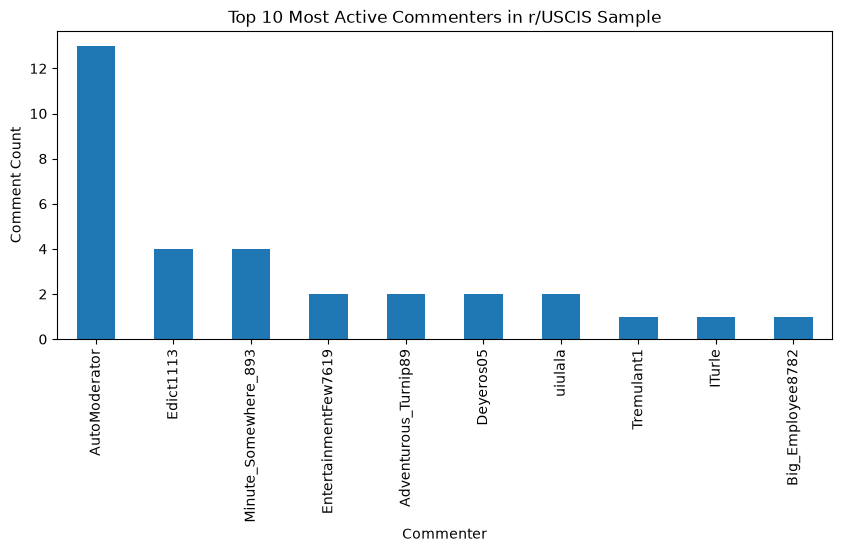

In [34]:
plt.figure(figsize=(10, 4))
comment_df[comment_df['author'] != '']['author'].value_counts()[:10].plot.bar()
plt.title('Top 10 Most Active Commenters in r/USCIS Sample')
plt.xlabel('Commenter')
plt.ylabel('Comment Count')
plt.show()

### Comment EDA: Score Distribution
Let's plot the distribution of comment scores (upvotes):

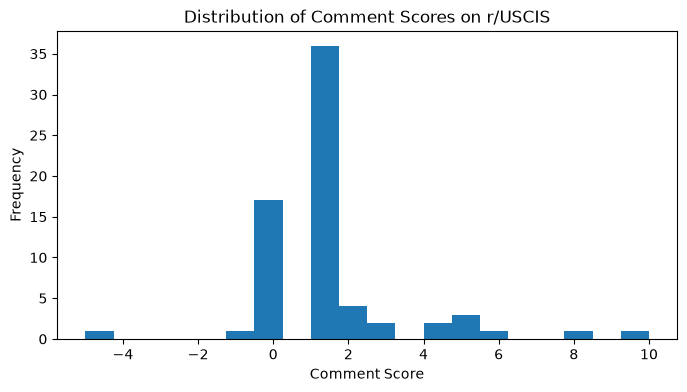

In [35]:
plt.figure(figsize=(8, 4))
comment_df['score'].plot.hist(bins=20)
plt.title('Distribution of Comment Scores on r/USCIS')
plt.xlabel('Comment Score')
plt.ylabel('Frequency')
plt.show()

## Challenge 3: N-Grams (Bigrams, Trigrams) and Collocations
We examine multi-word phrases (n-grams) and collocations to see which terms commonly appear together in USCIS post titles:
- **Bigrams**: Pairs of consecutive words (e.g. 'green card', 'field office')
- **Trigrams**: Triples of consecutive words (e.g. 'green card interview')
- **Collocations**: Words that co-occur unusually frequently compared to random chance, measured via Pointwise Mutual Information (PMI)

In [36]:
from nltk.collocations import BigramCollocationFinder, BigramAssocMeasures

# Bigrams
bigrams = list(nltk.bigrams(cleaned_words))
bigram_fd = nltk.FreqDist(bigrams)
print("Top 10 Bigrams in r/USCIS Post Titles:")
for bg, count in bigram_fd.most_common(10):
    print(f"  {bg[0]} {bg[1]}: {count}")

# Trigrams
trigrams = list(nltk.trigrams(cleaned_words))
trigram_fd = nltk.FreqDist(trigrams)
print("\nTop 10 Trigrams in r/USCIS Post Titles:")
for tg, count in trigram_fd.most_common(10):
    print(f"  {tg[0]} {tg[1]} {tg[2]}: {count}")

Top 10 Bigrams in r/USCIS Post Titles:
  green card: 47
  field office: 21
  interview scheduled: 14
  stem opt: 13
  congressional inquiry: 11
  still pending: 11
  i-485 approved: 11
  i-130 i-485: 11
  marriage-based aos: 10
  pending i-485: 10

Top 10 Trigrams in r/USCIS Post Titles:
  i-485 still pending: 6
  based green card: 5
  green card interview: 5
  marriage-based green card: 4
  green card approved: 4
  currently processing case: 4
  congressional inquiry response: 3
  i-485 interview scheduled: 3
  approved i-485 still: 3
  marriage based green: 3


<Axes: title={'center': 'Top 15 Bigrams in r/USCIS Post Titles'}, xlabel='Samples', ylabel='Counts'>

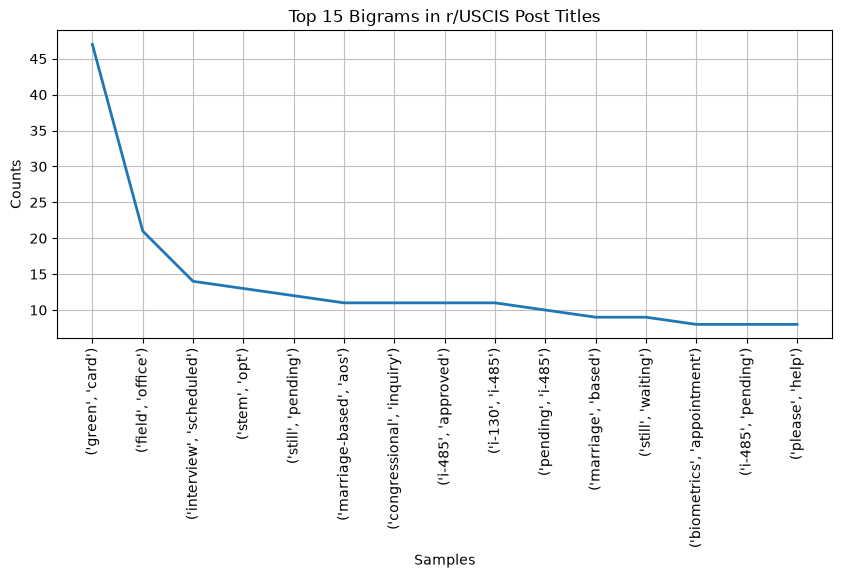

In [37]:
plt.figure(figsize=(10, 4))
bigram_fd.plot(15, title='Top 15 Bigrams in r/USCIS Post Titles')

### Bigram Collocations (PMI)
Collocations find statistically significant pairs using Pointwise Mutual Information (PMI):

In [37]:
finder = BigramCollocationFinder.from_words(cleaned_words)
finder.apply_freq_filter(3)  # Filter for bigrams occurring at least 3 times
bigram_measures = BigramAssocMeasures()

print("Top 10 Collocations by PMI:")
for col in finder.nbest(bigram_measures.pmi, 10):
    print(f"  {col[0]} {col[1]}")

Top 10 Collocations by PMI:
  adit stamp
  health insurance
  pro se
  speeding ticket
  stay away
  san jose
  j-1 withdrawal-spouse
  birth certificate
  action taken
  i-601 waiver


---
## Task 2: Prediction Log
Before you collect the data, write a one-sentence prediction of what you expect to find in the EDA analysis of your subreddit. After your analysis, note whether your observations. This log should cover at least **3 predictions** tied to your data. Use the scaffold below.

Fill in at least 3 rows *before* collecting the data. Add more rows if you like.

| # | My prediction (before analysis) | What I actually found | Was I right? |
|---|---|---|---|
| 1 | I think the most common words will be specific form numbers like I-485 and I-130, along with status updates like 'approved' and 'interview', since people mostly visit this subreddit to track their immigration cases. | Once stopwords were removed, form names and milestone words showed up the most, led by 'i-485' (137 times), 'interview' (116), 'approved' (102), 'pending' (58), 'card' (56), 'i-130' (51), and 'timeline' (51). | Yes |
| 2 | I expect most posts will have very low upvote scores (between 0 and 5) because people are just asking quick personal questions, but a few big approval celebration posts will get lots of upvotes. | The score distribution was heavily skewed to the right: half the posts had a score of only 1 or less (75th percentile was just 2), but a handful of big posts got upvotes all the way up to 765. | Yes |
| 3 | I think posts with higher scores will also have more comments, because exciting approval stories and urgent questions tend to get more replies and advice from the community. | The scatter plot confirmed this positive relationship: higher-scoring posts often had 15 to 50+ comments, while posts with 0 or 1 upvotes usually had only 2 or 3 replies. | Yes |

## Task 3: Critical Reflection
Reflect on the EDA that you had performed and say what you could do different and how that may impact your results? 3-5 sentences.

Looking back at my analysis, pulling only "hot" posts gave me a good look at what people are talking about right now, but it definitely favored recent threads and current backlog questions rather than the subreddit as a whole. If I did this again, I would pull posts using the "top" filter across the past year and include post timestamps (created_utc) so I could track how wait times and discussions change over different months. I also realized that words like "approved", "approving", and "approval" were counted separately in my word count; combining them with lemmatization would have given me a cleaner picture of the true top topics. Doing these things would have made my results much more representative of long-term immigration trends rather than just a single snapshot in time.

---
# Summary Analysis
For this assignment, I used PRAW to collect posts from the r/USCIS subreddit and saved them into an SQLite database for analysis. From my EDA, I found that most posts had low scores between 0 and 2 because users were just asking quick personal questions, while a few major approval posts got hundreds of upvotes and many comments. After cleaning out stopwords, the most common words and phrases were immigration forms and status milestones like I-485, interview, approved, and green card. Overall, the data clearly showed that people mainly use this subreddit to track their timelines, ask for help, and celebrate case approvals.

---
### AI Disclosure
I used Google Antigravity as an AI assistant to help troubleshoot code, implement the SQLite queries, comment extraction loop, and NLTK routines. All analyses, interpretations, prediction evaluations, and critical reflections in this assignment are my own.
